# Termômetro da Sala — previsão do índice de calor

**Global Solution 2026.2 (CitizenTech) — Machine Learning**

| Campo | Conteúdo |
|---|---|
| Problema | Nas tardes quentes, a sala de aula passa do limite seguro sem que ninguém meça, e a escola só reage quando alguém passa mal |
| Cidadão beneficiado | Professor(a) e turma de uma sala sem climatização; quem opera é a coordenação |
| O que o modelo faz | Prevê o **índice de calor da rua daqui a 2 horas**. A API soma a diferença medida entre a sala e a rua (o *delta* da sala, vindo do sensor ESP32) e mostra o nível previsto da sala no app e no desktop |
| Dados | Reais e públicos: INMET, estação automática A701 (São Paulo, Mirante de Santana), dados horários de 2022 a 2025 |
| Métricas | MAE do índice (°C) e F1 macro dos níveis, comparados com o baseline "daqui a 2 h = agora" |

Integrantes: Samuel Baecker — RM [preencher]

## 1. Dados e origem
Fonte: [dados históricos públicos do INMET](https://portal.inmet.gov.br/dadoshistoricos),
arquivos anuais `2022.zip`, `2023.zip`, `2024.zip` e `2025.zip`; estação automática
**A701, São Paulo — Mirante de Santana**, de 01/01/2022 a 31/12/2025 (hora em UTC).
Consulta às condições de uso e atribuição: [portal do INMET](https://portal.inmet.gov.br/).
Não se presume uma licença específica que não esteja documentada na fonte.

`extrair_a701.py` seleciona o único CSV `_A701_` de cada ZIP, decodifica Latin-1,
pula as oito linhas de metadados e lê o separador `;` e a vírgula decimal.
Usa `Data` (ou `DATA (YYYY-MM-DD)`), `Hora UTC` (ou `HORA (UTC)`),
`TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)` e
`UMIDADE RELATIVA DO AR, HORARIA (%)`. Exporta `data_hora_utc`, `temperatura_c`
e `umidade_pct` em `dados/inmet_a701.csv`, descartando registros sem data/hora,
temperatura ou umidade e valores vazios ou `-9999` nessas medições.
O CSV já está limpo: as ausências abaixo incluem horas não registradas ou descartadas,
sem permitir separar as causas. São Paulo é UTC−3 neste período.

**Reprodução / Colab:** dependências fixadas em `requirements.txt`. No Colab, envie
um ZIP da pasta `ml` pelo painel Arquivos, extraia em `/content` e execute
`%cd /content/ml`, depois `%pip install -r requirements.txt`. Abra este notebook
pelo menu Arquivo → Fazer upload de notebook e execute todas as células.
Localmente, execute a partir de `ml` ou da raiz do projeto.

In [1]:
import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from pathlib import Path
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, classification_report
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score

PASTA = Path('ml') if Path('ml/dados/inmet_a701.csv').exists() else Path('.')
df = pd.read_csv(PASTA / 'dados/inmet_a701.csv', parse_dates=['data_hora_utc'])
df['data_hora_utc'] = pd.to_datetime(df['data_hora_utc'], utc=True)
assert df[['temperatura_c', 'umidade_pct']].notna().all().all()
assert df.temperatura_c.between(-90, 60).all() and df.umidade_pct.between(0, 100).all()
print('timestamps duplicados removidos:', df.data_hora_utc.duplicated().sum())
df = df.drop_duplicates('data_hora_utc').set_index('data_hora_utc').sort_index()
df['local'] = df.index.tz_convert('America/Sao_Paulo')
# vetor de teste do relógio (CONTRATO.md): 15/01/2026 às 1700 UTC = 14h em São Paulo
assert pd.Timestamp('2026-01-15 17:00', tz='UTC').tz_convert('America/Sao_Paulo').hour == 14
print(len(df), 'horas válidas de', df.index.min().date(), 'a', df.index.max().date())
df.describe()[['temperatura_c', 'umidade_pct']]

timestamps duplicados removidos: 0
34786 horas válidas de 2022-01-01 a 2025-12-31


,temperatura_c,umidade_pct
count,34786.000000,34786.000000
mean,20.799747,68.252832
std,4.697019,17.779404
min,5.800000,12.000000
25%,17.500000,56.000000
50%,20.500000,73.000000
75%,23.700000,82.000000
max,37.200000,100.000000


In [2]:
calendario = pd.date_range('2022-01-01', '2026-01-01', freq='h', inclusive='left', tz='UTC')
assert df.index.isin(calendario).all()
faltantes = calendario.difference(df.index)
por_ano = pd.DataFrame({'esperadas': pd.Series(1, index=calendario).groupby(calendario.year).sum(),
                       'validas': df.groupby(df.index.year).size()})
por_ano['ausentes_ou_descartadas'] = por_ano.esperadas - por_ano.validas
por_ano['ausentes_pct'] = (100 * por_ano.ausentes_ou_descartadas / por_ano.esperadas).round(2)
display(por_ano)
grupos = pd.Series(faltantes, index=faltantes).diff().ne(pd.Timedelta(hours=1)).cumsum()
buracos = pd.DataFrame({'hora': faltantes, 'grupo': grupos.to_numpy()}).groupby('grupo').hora.agg(['min', 'max', 'size'])
print('Buracos contínuos (incluindo bordas do período):', len(buracos))
display(buracos.sort_values('size', ascending=False).head(10))
assert por_ano.ausentes_ou_descartadas.sum() == len(faltantes)

,esperadas,validas,ausentes_ou_descartadas,ausentes_pct
2022,8760,8760,0,0.00
2023,8760,8548,212,2.42
2024,8784,8765,19,0.22
2025,8760,8713,47,0.54


Buracos contínuos (incluindo bordas do período): 92


,min,max,size
grupo,,,
40,2023-11-26 07:00:00+00:00,2023-11-28 12:00:00+00:00,54
39,2023-11-21 10:00:00+00:00,2023-11-22 13:00:00+00:00,28
89,2025-12-02 04:00:00+00:00,2025-12-02 18:00:00+00:00,15
34,2023-09-28 21:00:00+00:00,2023-09-29 10:00:00+00:00,14
15,2023-05-28 02:00:00+00:00,2023-05-28 13:00:00+00:00,12
19,2023-07-09 06:00:00+00:00,2023-07-09 16:00:00+00:00,11
57,2024-04-05 14:00:00+00:00,2024-04-05 22:00:00+00:00,9
24,2023-08-05 03:00:00+00:00,2023-08-05 11:00:00+00:00,9
20,2023-07-14 04:00:00+00:00,2023-07-14 12:00:00+00:00,9


## 2. Índice de calor
Fórmula da NOAA (Rothfusz, com os ajustes de umidade), a mesma do ESP32 e da API. Os 4 casos do contrato conferem a implementação.

In [3]:
def indice_calor_c(temp_c, umidade):
    t = temp_c * 9 / 5 + 32
    rh = umidade
    simples = 0.5 * (t + 61.0 + (t - 68.0) * 1.2 + rh * 0.094)
    if (simples + t) / 2 < 80:
        hi = simples
    else:
        hi = (-42.379 + 2.04901523 * t + 10.14333127 * rh - 0.22475541 * t * rh - 0.00683783 * t * t
              - 0.05481717 * rh * rh + 0.00122874 * t * t * rh + 0.00085282 * t * rh * rh - 0.00000199 * t * t * rh * rh)
        if rh < 13 and 80 <= t <= 112:
            hi -= ((13 - rh) / 4) * math.sqrt((17 - abs(t - 95)) / 17)
        elif rh > 85 and 80 <= t <= 87:
            hi += ((rh - 85) / 10) * ((87 - t) / 5)
    return round((hi - 32) * 5 / 9, 1)

NIVEIS = ['normal', 'atencao', 'cuidado', 'perigo']
def nivel(i):
    return 'normal' if i < 27 else 'atencao' if i < 32 else 'cuidado' if i < 41 else 'perigo'

for t, u, esperado, n in [(24.0, 40, 23.5, 'normal'), (30.0, 50, 31.0, 'atencao'), (33.4, 58, 39.8, 'cuidado'), (38.0, 70, 62.5, 'perigo')]:
    assert indice_calor_c(t, u) == esperado and nivel(esperado) == n

df['indice'] = [indice_calor_c(t, u) for t, u in zip(df.temperatura_c, df.umidade_pct)]
df['nivel'] = df['indice'].map(nivel)
df['nivel'].value_counts()

nivel
normal     30792
atencao     3745
cuidado      249
Name: count, dtype: int64

Quando o calor aparece: índice médio por hora local nos meses de verão (dezembro a março).

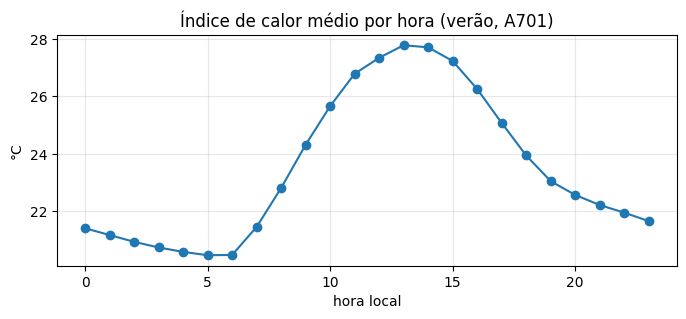

In [4]:
verao = df[df.local.dt.month.isin([12, 1, 2, 3])]
verao.groupby(verao.local.dt.hour)['indice'].mean().plot(marker='o', figsize=(8, 3), title='Índice de calor médio por hora (verão, A701)')
plt.xlabel('hora local'); plt.ylabel('°C'); plt.grid(alpha=.3); plt.show()

## 3. Atributos e alvo
Só atributos que **existem em produção** (o boletim horário do INMET): temperatura, umidade, hora local (em seno e cosseno, para o modelo entender que 23h fica perto de 0h), mês e variação da temperatura na última hora. O alvo é o índice de calor **2 horas depois**. Só entram linhas com as horas vizinhas presentes (sem buracos).

In [5]:
uma_h, duas_h = pd.Timedelta(hours=1), pd.Timedelta(hours=2)
anterior = df['temperatura_c'].reindex(df.index - uma_h).to_numpy()
futuro = df['indice'].reindex(df.index + duas_h).to_numpy()
X = pd.DataFrame({
    'temperatura_c': df.temperatura_c,
    'umidade_pct': df.umidade_pct,
    'hora_sen': np.sin(2 * np.pi * df.local.dt.hour / 24),
    'hora_cos': np.cos(2 * np.pi * df.local.dt.hour / 24),
    'mes_sen': np.sin(2 * np.pi * df.local.dt.month / 12),
    'mes_cos': np.cos(2 * np.pi * df.local.dt.month / 12),
    'variacao_1h': df.temperatura_c.to_numpy() - anterior,
}, index=df.index)
dados = X.assign(indice_agora=df['indice'], alvo=futuro).dropna()
ano = dados.index.year
treino = dados[(ano <= 2023) & (dados.index + duas_h < pd.Timestamp('2024-01-01', tz='UTC'))]
valid = dados[(ano == 2024) & (dados.index + duas_h < pd.Timestamp('2025-01-01', tz='UTC'))]
teste = dados[ano == 2025]
ATRIBUTOS = list(X.columns)
print('dropna (sem hora anterior ou alvo +2 h):', len(df) - len(dados))
print('exemplos excluídos nas fronteiras:', len(dados) - len(treino) - len(valid) - len(teste))
print('treino', len(treino), '| validação', len(valid), '| teste', len(teste))
assert treino.index.max() + duas_h < valid.index.min()
assert valid.index.max() + duas_h < teste.index.min()

dropna (sem hora anterior ou alvo +2 h): 205
exemplos excluídos nas fronteiras: 4
treino 17192 | validação 8740 | teste 8645


### Distribuições e correlação (treino)
A análise do alvo usa apenas o treino, preservando 2025 para a avaliação final.
As frequências evidenciam o desbalanceamento: MAE e acurácia global podem esconder
erros em `cuidado`. Correlação mede associação linear, sem demonstrar causalidade;
seno e cosseno devem ser interpretados em conjunto.

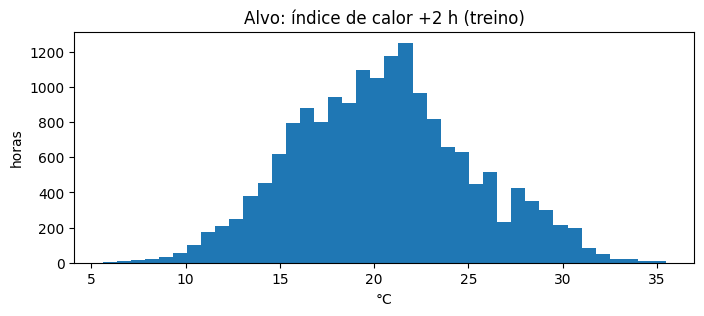

,horas,percentual
alvo,,
normal,15420,89.693
atencao,1668,9.702
cuidado,104,0.605
perigo,0,0.000


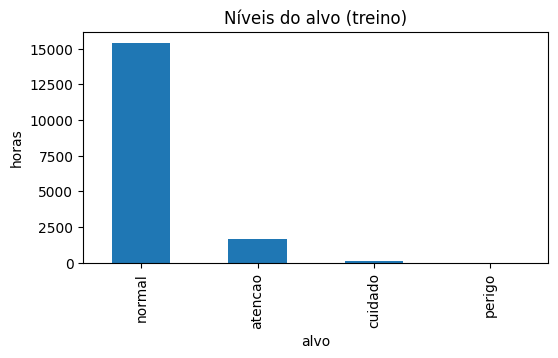

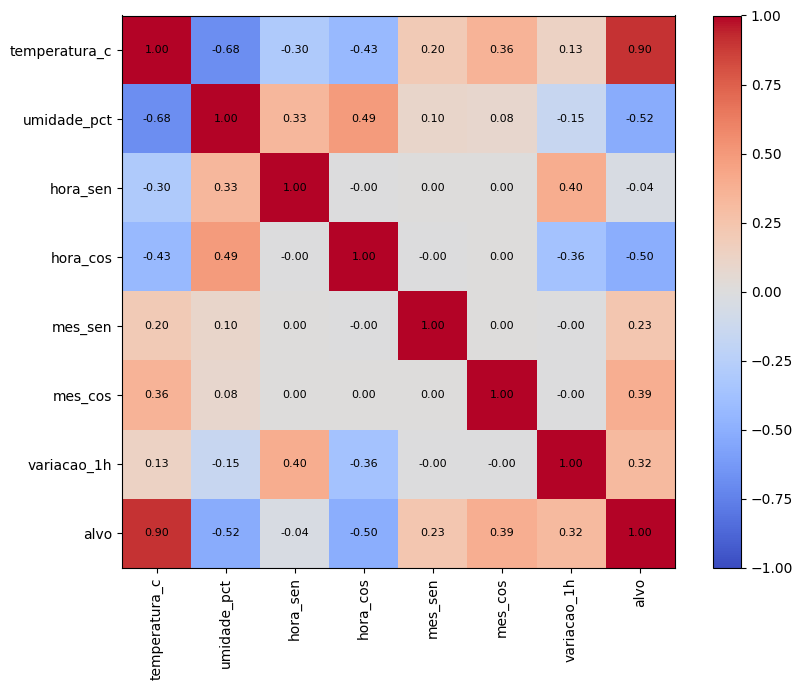

In [6]:
treino.alvo.plot.hist(bins=40, figsize=(8, 3), title='Alvo: índice de calor +2 h (treino)')
plt.xlabel('°C'); plt.ylabel('horas'); plt.show()
contagens = treino.alvo.map(nivel).value_counts().reindex(NIVEIS, fill_value=0)
display(pd.DataFrame({'horas': contagens, 'percentual': (100 * contagens / len(treino)).round(3)}))
contagens.plot.bar(title='Níveis do alvo (treino)', figsize=(6, 3))
plt.ylabel('horas'); plt.show()
correlacao = treino[ATRIBUTOS + ['alvo']].corr()
fig, ax = plt.subplots(figsize=(9, 7))
imagem = ax.imshow(correlacao, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(correlacao)), correlacao.columns, rotation=90)
ax.set_yticks(range(len(correlacao)), correlacao.columns)
for i in range(len(correlacao)):
    for j in range(len(correlacao)):
        ax.text(j, i, f'{correlacao.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(imagem, ax=ax); plt.tight_layout(); plt.show()

## 4. Modelos
Divisão **por tempo** (sem embaralhar): treina em 2022–2023, ajusta a árvore com
`TimeSeriesSplit` expansivo de 3 blocos e intervalo de 2 exemplos, escolhe entre
linear e árvore pelo menor MAE em 2024 e só no fim mede em 2025. Os modelos
permanecem ajustados apenas em 2022–2023, sem retreino após a seleção.
O baseline "daqui a 2 h = agora" serve como referência. O critério de seleção é
MAE, não recall de risco; essa escolha pode favorecer um modelo que perde episódios
raros. O teste final serve para reportar esse limite, sem reajustar a escolha.

In [7]:
def avalia(nome, previsto, real):
    reais = [nivel(v) for v in real]
    presentes = [n for n in NIVEIS if n in reais]  # 'perigo' não aparece na A701 em 2022-2025: fica fora da média
    return {'modelo': nome, 'MAE (°C)': round(mean_absolute_error(real, previsto), 3),
            'RMSE (°C)': round(mean_squared_error(real, previsto, squared=False), 3),
            'R²': round(r2_score(real, previsto), 3),
            'F1 macro (níveis)': round(f1_score(reais, [nivel(v) for v in previsto], average='macro', labels=presentes, zero_division=0), 3)}

cv = TimeSeriesSplit(n_splits=3, gap=2)
for antes, depois in cv.split(treino):
    assert treino.index[antes[-1]] + duas_h < treino.index[depois[0]]
# gap=2 impede que o alvo +2 h do treino alcance o próximo bloco.
busca = GridSearchCV(DecisionTreeRegressor(random_state=42),
                    {'max_depth': [4, 6, 8], 'min_samples_leaf': [30, 50]},
                    scoring='neg_mean_absolute_error', cv=cv)
busca.fit(treino[ATRIBUTOS], treino.alvo)
print('Busca: 6 combinações × 3 blocos, escolhidas pelo menor MAE; profundidades limitam complexidade e folhas reduzem sobreajuste.')
display(pd.DataFrame(busca.cv_results_)[['param_max_depth', 'param_min_samples_leaf', 'mean_test_score', 'std_test_score']]
        .assign(MAE_CV=lambda t: -t.mean_test_score).drop(columns='mean_test_score').sort_values('MAE_CV'))
print('Linear, MAE médio na mesma CV:', -cross_val_score(LinearRegression(), treino[ATRIBUTOS], treino.alvo,
                                                       cv=cv, scoring='neg_mean_absolute_error').mean())
print('Melhor árvore:', busca.best_params_)
linear = LinearRegression().fit(treino[ATRIBUTOS], treino.alvo)
arvore = busca.best_estimator_
candidatos = {'baseline (agora)': lambda d: d.indice_agora.to_numpy(),
              'regressão linear': lambda d: linear.predict(d[ATRIBUTOS]),
              'árvore ajustada': lambda d: arvore.predict(d[ATRIBUTOS])}
validacao = pd.DataFrame([avalia(n, f(valid), valid.alvo) for n, f in candidatos.items()])
validacao

Busca: 6 combinações × 3 blocos, escolhidas pelo menor MAE; profundidades limitam complexidade e folhas reduzem sobreajuste.


,param_max_depth,param_min_samples_leaf,std_test_score,MAE_CV
4,8,30,0.097119,1.053585
5,8,50,0.094795,1.088839
2,6,30,0.086172,1.157752
3,6,50,0.094683,1.168170
0,4,30,0.131030,1.433306
1,4,50,0.131126,1.433581


Linear, MAE médio na mesma CV: 1.0919029314928042
Melhor árvore: {'max_depth': 8, 'min_samples_leaf': 30}


,modelo,MAE (°C),RMSE (°C),R²,F1 macro (níveis)
0,baseline (agora),1.479,2.084,0.809,0.652
1,regressão linear,1.098,1.501,0.901,0.671
2,árvore ajustada,0.981,1.390,0.915,0.618


### Importância dos atributos
Coeficientes da linear multiplicados pelo desvio padrão de cada atributo no treino:
variação prevista em °C para +1 desvio padrão, mantendo os demais atributos constantes.
A árvore usa redução de impureza, que pode distribuir importância entre atributos
correlacionados; as duas escalas não são diretamente comparáveis.

,coeficiente_padronizado,importancia_arvore
temperatura_c,4.714801,0.885529
umidade_pct,0.854956,0.011770
hora_sen,0.734070,0.050316
hora_cos,-0.558897,0.015693
mes_sen,0.052518,0.000756
mes_cos,0.090752,0.000182
variacao_1h,0.526122,0.035753


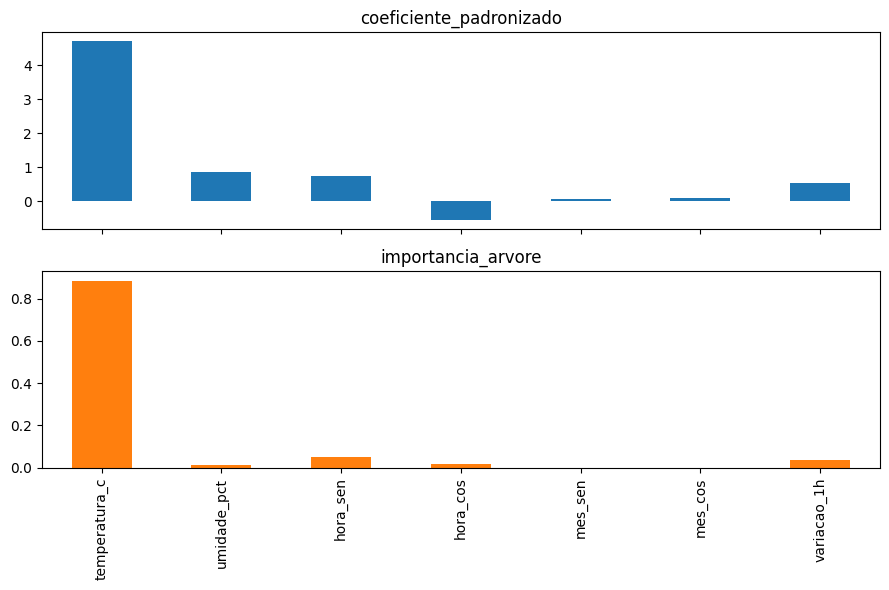

In [8]:
importancias = pd.DataFrame({'coeficiente_padronizado': linear.coef_ * treino[ATRIBUTOS].std(ddof=0),
                              'importancia_arvore': arvore.feature_importances_}, index=ATRIBUTOS)
display(importancias)
importancias.plot.bar(subplots=True, figsize=(9, 6), legend=False)
plt.tight_layout(); plt.show()

In [9]:
escolhido = validacao[validacao.modelo != 'baseline (agora)'].sort_values('MAE (°C)').iloc[0].modelo
print('modelo escolhido na validação:', escolhido)
previsoes_teste = {n: f(teste) for n, f in candidatos.items()}
resultado_teste = pd.DataFrame([avalia(n, p, teste.alvo) for n, p in previsoes_teste.items()])
resultado_teste

modelo escolhido na validação: árvore ajustada


,modelo,MAE (°C),RMSE (°C),R²,F1 macro (níveis)
0,baseline (agora),1.442,2.021,0.834,0.667
1,regressão linear,1.053,1.451,0.914,0.745
2,árvore ajustada,0.958,1.364,0.924,0.660


### Onde o modelo acerta e onde erra (teste, 2025)

O `classification_report` inclui os quatro níveis: sua média macro inclui `perigo` com suporte zero. A tabela de regressão usa F1 macro apenas dos níveis presentes, por isso as duas médias diferem.

baseline (agora)
              precision    recall  f1-score   support

      normal      0.963     0.963     0.963      7697
     atencao      0.661     0.658     0.659       900
     cuidado      0.383     0.375     0.379        48
      perigo      0.000     0.000     0.000         0

   micro avg      0.928     0.928     0.928      8645
   macro avg      0.502     0.499     0.500      8645
weighted avg      0.928     0.928     0.928      8645



árvore ajustada


              precision    recall  f1-score   support

      normal      0.972     0.982     0.977      7697
     atencao      0.791     0.752     0.771       900
     cuidado      0.583     0.146     0.233        48
      perigo      0.000     0.000     0.000         0

   micro avg      0.953     0.953     0.953      8645
   macro avg      0.586     0.470     0.495      8645
weighted avg      0.951     0.953     0.951      8645



,precision,recall,f1-score,support
baseline (agora),0.382979,0.375000,0.378947,48.0
árvore ajustada,0.583333,0.145833,0.233333,48.0


Cuidado no teste: 48.0 horas; recall do modelo: 0.146 | baseline: 0.375


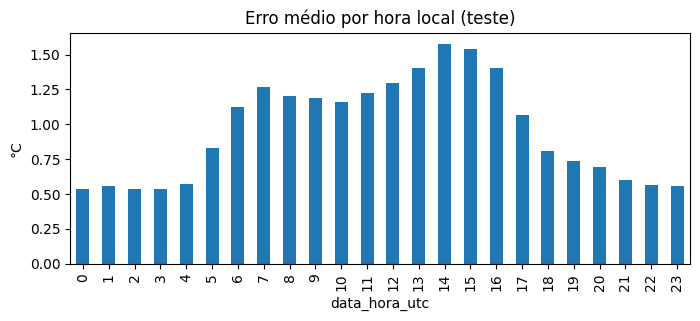

previsto,atencao,cuidado,normal
real,,,
atencao,677,4,219
cuidado,39,7,2
normal,140,1,7556


In [10]:
prev = previsoes_teste[escolhido]
relatorios = {}
for nome in ['baseline (agora)', escolhido]:
    reais, previstos = teste.alvo.map(nivel), pd.Series(previsoes_teste[nome]).map(nivel)
    print(nome)
    print(classification_report(reais, previstos, labels=NIVEIS, zero_division=0, digits=3))
    relatorios[nome] = classification_report(reais, previstos, labels=NIVEIS, zero_division=0, output_dict=True)
display(pd.DataFrame({nome: rel['cuidado'] for nome, rel in relatorios.items()}).T)
print('Cuidado no teste:', relatorios[escolhido]['cuidado']['support'],
      'horas; recall do modelo:', round(relatorios[escolhido]['cuidado']['recall'], 3),
      '| baseline:', round(relatorios['baseline (agora)']['cuidado']['recall'], 3))
erro = pd.Series(np.abs(prev - teste.alvo.to_numpy()), index=teste.index)
erro.groupby(teste.index.tz_convert('America/Sao_Paulo').hour).mean().plot(kind='bar', figsize=(8, 3), title='Erro médio por hora local (teste)')
plt.ylabel('°C'); plt.show()
pd.crosstab(pd.Series([nivel(v) for v in teste.alvo], name='real'), pd.Series([nivel(v) for v in prev], name='previsto'))

## 5. Exportar `modelo.json`
A API (C#) carrega este arquivo e aplica o modelo: não há servidor Python em produção. O JSON leva os atributos na ordem, os coeficientes (linear) ou os nós da árvore, e as métricas de teste.

In [11]:
def arvore_json(m):
    t = m.tree_
    def no(i):
        if t.children_left[i] == -1:
            return {'valor': round(float(t.value[i][0][0]), 4)}
        return {'atributo': ATRIBUTOS[t.feature[i]], 'limite': round(float(t.threshold[i]), 6),
                'menor_ou_igual': no(t.children_left[i]), 'maior': no(t.children_right[i])}
    return no(0)

metricas = resultado_teste.set_index('modelo').loc[escolhido].to_dict()
base = resultado_teste.set_index('modelo').loc['baseline (agora)'].to_dict()
modelo = {'versao': 1, 'alvo': 'indice_calor_c em 2 h', 'horizonte_horas': 2, 'atributos': ATRIBUTOS,
          'fonte': 'INMET A701, horário, 2022-2025 (treino 2022-2023, validação 2024, teste 2025)',
          'metricas_teste': metricas, 'baseline_teste': base}
if escolhido == 'regressão linear':
    modelo |= {'tipo': 'linear', 'intercepto': round(float(linear.intercept_), 6),
               'coeficientes': {a: round(float(c), 6) for a, c in zip(ATRIBUTOS, linear.coef_)}}
else:
    modelo |= {'tipo': 'arvore', 'raiz': arvore_json(arvore)}
with open(PASTA / 'modelo.json', 'w', encoding='utf-8') as f:
    json.dump(modelo, f, ensure_ascii=False, indent=1)
print('modelo.json:', modelo['tipo'], metricas)

modelo.json: arvore {'MAE (°C)': 0.958, 'RMSE (°C)': 1.364, 'R²': 0.924, 'F1 macro (níveis)': 0.66}


Conferência: a mesma previsão feita lendo o JSON (como a API vai fazer) bate com o modelo do scikit-learn.

In [12]:
def prever_json(m, linha):
    if m['tipo'] == 'linear':
        return m['intercepto'] + sum(m['coeficientes'][a] * linha[a] for a in m['atributos'])
    n = m['raiz']
    while 'valor' not in n:
        n = n['menor_ou_igual'] if linha[n['atributo']] <= n['limite'] else n['maior']
    return n['valor']

with open(PASTA / 'modelo.json', encoding='utf-8') as f:
    exportado = json.load(f)
amostra = teste.sample(200, random_state=1)
referencia = pd.Series(prev, index=teste.index)
diferenca = max(abs(prever_json(exportado, r) - referencia.loc[i]) for i, r in amostra.iterrows())
assert diferenca < 0.01, diferenca
print('diferença máxima JSON x scikit-learn:', round(diferenca, 5))

diferença máxima JSON x scikit-learn: 5e-05


## 6. Conclusões e limitações
- O modelo é comparado com o baseline "daqui a 2 h = agora", que é o que uma pessoa faria olhando o termômetro. A tabela de teste mostra quanto ele ganha.
- `Cuidado` é raro: o relatório mostra seu recall e a comparação com o baseline, pois o F1 macro não basta para avaliar a segurança. `Perigo` não aparece nesta base; suporte zero não comprova capacidade de previsão desse nível. Não há garantia de detectar todos os episódios críticos, nem validação da previsão dentro da sala.
- Nesta execução, a árvore escolhida pelo MAE de validação atinge MAE de **0,958 °C**, RMSE de **1,364 °C** e R² de **0,924** em 2025. Porém reconhece só **7 de 48** horas de `cuidado` (recall **14,6%**), abaixo do baseline (**18 de 48**, **37,5%**); erra 39 como `atencao` e 2 como `normal`. A melhora média não demonstra melhora no alerta crítico. A linear tem F1 macro maior (0,745 contra 0,660 da árvore), mas não foi escolhida pelo critério definido. Uma futura revisão do critério deve usar treino/validação e um novo período de teste, sem escolher pelo resultado de 2025.
- O aviso com 2 h de antecedência apoia a decisão da coordenação de hidratar, ventilar ou realocar a turma, ligado ao **ODS 3.d** (alerta precoce e redução de riscos à saúde). O impacto deve ser medido por aulas em Perigo sem ação, ainda sem evidência medida neste estudo; a previsão não substitui a leitura atual nem os protocolos da escola.
- A previsão é da **rua**. A sala entra pela regra do delta (média das últimas 3 h da diferença sala − rua, medida pelo ESP32), que é simples e auditável. Ela supõe que a diferença das últimas 3 h se mantém nas próximas 2 h; no fim da tarde tende a superestimar.
- Os dados são públicos e reais (INMET). As leituras da sala no Wokwi e no modo demonstração são simuladas, e o README diz isso.
- Próximo passo: com uma semana de leituras reais da sala (termo-higrômetro anotado pelo professor), avaliar a previsão completa da sala contra o que a sala realmente teve 2 h depois.